# Predicting Diabetes Risk from Population Health Survey Indicators: Traditional ML vs Deep Learning

**ALU Machine Learning, Summative: Model Training and Evaluation**

| Resource | Link |
|---|---|
| GitHub repository | *paste link here* |
| Google Drive folder (raw data zip + best models) | *paste link here* |
| Video presentation | *paste link here* |

**Problem.** Can routinely collected, low-cost survey indicators (blood pressure, BMI, general health, age, income, lifestyle) identify people who are likely to have diabetes or prediabetes, so that limited screening resources in under-served communities can be directed to the people who need them most?

**Dataset.** CDC Diabetes Health Indicators (UCI ML Repository, id 891), derived from the 2015 BRFSS survey: about 253,680 respondents, 21 features, binary target `Diabetes_binary` (0 = no diabetes, 1 = prediabetes or diabetes).

**Notebook map**

1. Setup and reproducibility
2. Data loading and exploratory analysis
3. Preprocessing and feature engineering
4. Experiment infrastructure (logging, metrics)
5. Traditional ML experiments (scikit-learn)
6. Deep learning experiments (TensorFlow/Keras with `tf.data`)
7. Results table
8. Final evaluation: confusion matrices, ROC/PR, learning curves, bias-variance, error analysis
9. Saving artifacts
10. Conclusions

> Cells marked **Your interpretation** are intentionally blank. Fill them in with your own reading of the outputs, because the rubric rewards explaining *why* results changed.

## 1. Setup and reproducibility

Install dependencies (Colab), fix every random seed, and define the global configuration. `FAST_DEBUG = True` runs the whole notebook on a small subsample with few epochs so you can check that every cell works before the full run.

In [ ]:
!pip install -q ucimlrepo wandb tabulate tensorboard

In [ ]:
import os, random, json, time, warnings, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold, learning_curve
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, balanced_accuracy_score, precision_recall_curve,
                             roc_curve, ConfusionMatrixDisplay, classification_report, confusion_matrix)

os.environ["WANDB_MODE"] = "online"          # logs stay on disk, no account needed
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import tensorflow as tf

SEED = 42
FAST_DEBUG = False        # True = tiny end-to-end check, False = full run

random.seed(SEED); np.random.seed(SEED); os.environ["PYTHONHASHSEED"] = str(SEED)
tf.keras.utils.set_random_seed(SEED)
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

DATA_DIR = Path("data/raw");        DATA_DIR.mkdir(parents=True, exist_ok=True)
ART_DIR = Path("artifacts");        ART_DIR.mkdir(exist_ok=True)
FIG_DIR = Path("figures");          FIG_DIR.mkdir(exist_ok=True)
LOG_DIR = Path("logs");             LOG_DIR.mkdir(exist_ok=True)

# size knobs
if FAST_DEBUG:
    N_ROWS, N_TUNE, N_SVM, N_TRSUB, N_ITER, EPOCH_SCALE = 30_000, 4_000, 3_000, 5_000, 2, 0.1
else:
    N_ROWS, N_TUNE, N_SVM, N_TRSUB, N_ITER, EPOCH_SCALE = None, 40_000, 15_000, 30_000, 12, 1.0

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

print("TensorFlow", tf.__version__, "| GPUs:", len(tf.config.list_physical_devices("GPU")))

TensorFlow 2.21.0 | GPUs: 1


## 2. Data loading and exploratory analysis

The data comes from the UCI repository (id 891, open licence, CC BY 4.0). The first run downloads it to `data/raw/` and caches a CSV there. **That folder is git-ignored**: the raw file goes into the Google Drive zip, never into GitHub.

If `ucimlrepo` is unavailable, download the CSV manually from the UCI page and place it at `data/raw/diabetes_binary_health_indicators_BRFSS2015.csv`.

In [ ]:
TARGET = "Diabetes_binary"
CSV_PATH = DATA_DIR / "diabetes_binary_health_indicators_BRFSS2015.csv"

def load_raw():
    if CSV_PATH.exists():
        return pd.read_csv(CSV_PATH)
    from ucimlrepo import fetch_ucirepo
    ds = fetch_ucirepo(id=891)
    df = pd.concat([ds.data.targets, ds.data.features], axis=1)
    df.to_csv(CSV_PATH, index=False)
    return df

raw = load_raw()
RAW_ROWS = len(raw)
print(f"Raw rows: {RAW_ROWS:,} | columns: {raw.shape[1]}  (requirement: at least 20,000 rows before preprocessing)")
if N_ROWS:
    raw = raw.sample(N_ROWS, random_state=SEED).reset_index(drop=True)
raw.head()

Raw rows: 253,680 | columns: 22  (requirement: at least 20,000 rows before preprocessing)


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0,1,1,1,40,1,0,0,0,0,...,1,0,5,18,15,1,0,9,4,3
1,0,0,0,0,25,1,0,0,1,0,...,0,1,3,0,0,0,0,7,6,1
2,0,1,1,1,28,0,0,0,0,1,...,1,1,5,30,30,1,0,9,4,8
3,0,1,0,1,27,0,0,0,1,1,...,1,0,2,0,0,0,0,11,3,6
4,0,1,1,1,24,0,0,0,1,1,...,1,0,2,3,0,0,0,11,5,4


In [ ]:
display(raw.dtypes.to_frame("dtype").T)
print("Missing values per column:", int(raw.isna().sum().sum()))
print("Exact duplicate rows     :", int(raw.duplicated().sum()), f"({raw.duplicated().mean():.1%})")
display(raw.describe().T[["mean", "std", "min", "50%", "max"]].round(2))

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
dtype,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,...,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64


Missing values per column: 0
Exact duplicate rows     : 24206 (9.5%)


,mean,std,min,50%,max
Diabetes_binary,0.14,0.35,0.0,0.0,1.0
HighBP,0.43,0.49,0.0,0.0,1.0
HighChol,0.42,0.49,0.0,0.0,1.0
CholCheck,0.96,0.19,0.0,1.0,1.0
BMI,28.38,6.61,12.0,27.0,98.0
Smoker,0.44,0.50,0.0,0.0,1.0
Stroke,0.04,0.20,0.0,0.0,1.0
HeartDiseaseorAttack,0.09,0.29,0.0,0.0,1.0
PhysActivity,0.76,0.43,0.0,1.0,1.0
Fruits,0.63,0.48,0.0,1.0,1.0


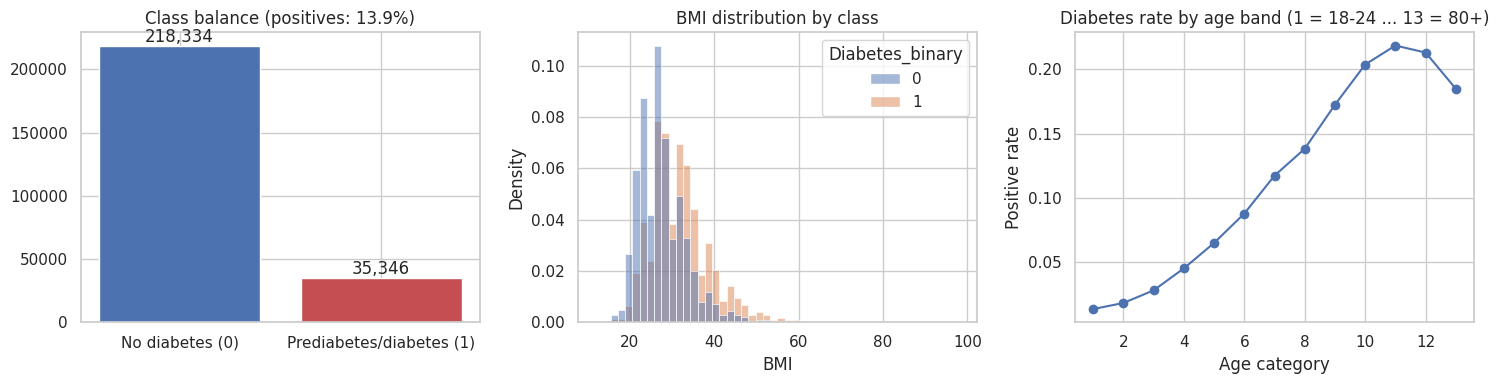

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
counts = raw[TARGET].value_counts().sort_index()
axes[0].bar(["No diabetes (0)", "Prediabetes/diabetes (1)"], counts.values, color=["#4c72b0", "#c44e52"])
axes[0].set_title(f"Class balance (positives: {counts[1] / counts.sum():.1%})")
for i, v in enumerate(counts.values): axes[0].text(i, v, f"{v:,}", ha="center", va="bottom")

sns.histplot(data=raw, x="BMI", hue=TARGET, bins=50, stat="density", common_norm=False, ax=axes[1])
axes[1].set_title("BMI distribution by class")

rate = raw.groupby("Age")[TARGET].mean()
axes[2].plot(rate.index, rate.values, marker="o")
axes[2].set_title("Diabetes rate by age band (1 = 18-24 ... 13 = 80+)")
axes[2].set_xlabel("Age category"); axes[2].set_ylabel("Positive rate")
savefig("eda_overview"); plt.show()

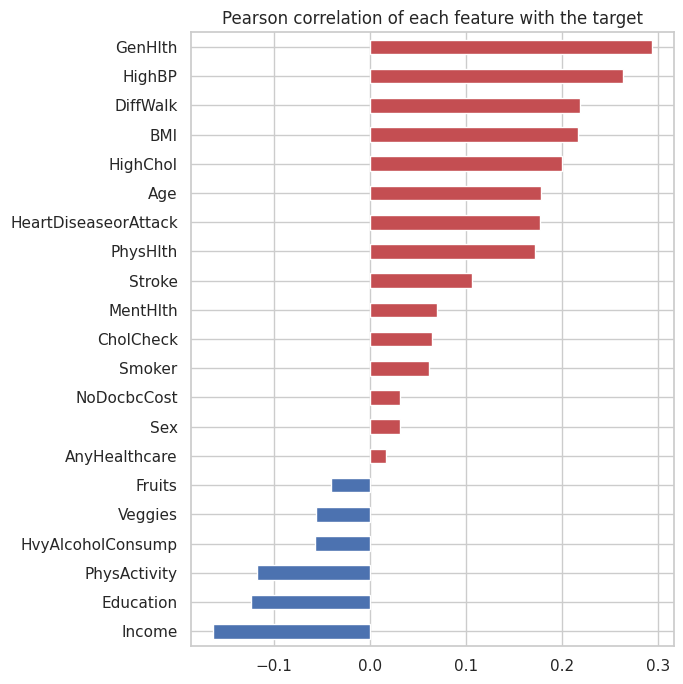

In [ ]:
corr = raw.corr()[TARGET].drop(TARGET).sort_values()
plt.figure(figsize=(7, 7))
corr.plot.barh(color=np.where(corr > 0, "#c44e52", "#4c72b0"))
plt.title("Pearson correlation of each feature with the target")
savefig("eda_target_correlation"); plt.show()

My Interpretation (EDA): The target is imbalanced: only 13.9% of the 253,680 respondents are positive (35,346), so a model that says "no diabetes" for everyone would already get about 86% accuracy. That is why I use ROC-AUC and PR-AUC as the main metrics, with recall and F1 next to them. The strongest correlations with the target are GenHlth, HighBP, DiffWalk, BMI and HighChol on the positive side, and Income, Education and PhysActivity on the negative side. BMI is right-skewed with a long tail up to 98. The diabetes group sits to the right of the non-diabetes group, but they overlap a lot, so BMI alone will not separate them. The diabetes rate rises steadily with age, from about 1% in the youngest band to about 22% at band 11, then drops slightly in the oldest band. So I expect older, higher-BMI, lower-income respondents to be easier to flag, and young respondents harder because they have very few positives.

## 3. Preprocessing and feature engineering

Decisions, in order, and why:

1. **Remove exact duplicates before splitting.** BRFSS answers are mostly small integers, so many respondents are identical. If duplicates straddle the train and validation sets the evaluation is optimistic (leakage).
2. **Stratified 70/15/15 split.** Stratification keeps the roughly 14 percent positive rate identical in all three sets. Validation is used for model selection and threshold choice; the test set is touched once at the end.
3. **Outliers.** BMI has implausible extremes. It is winsorised at the 0.5th and 99.5th percentile *of the training set only*.
4. **Scaling.** Continuous and ordinal columns are standardised with statistics from the training set (needed for logistic regression, SVM and the neural networks; harmless for trees). Binary columns pass through unchanged.
5. **Missing values.** None in this dataset (checked above), so no imputation is required; the check is kept in the pipeline so it fails loudly if that changes.
6. **Engineered features** (six, each tied to a health rationale) are tested in an ablation so their value is measured rather than assumed.

In [ ]:
BIN_BASE = ["HighBP", "HighChol", "CholCheck", "Smoker", "Stroke", "HeartDiseaseorAttack", "PhysActivity",
            "Fruits", "Veggies", "HvyAlcoholConsump", "AnyHealthcare", "NoDocbcCost", "DiffWalk", "Sex"]
NUM_BASE = ["BMI", "GenHlth", "MentHlth", "PhysHlth", "Age", "Education", "Income"]
ENG_NUM = ["comorbidity_count", "unhealthy_days", "lifestyle_score", "age_bmi", "bmi_category", "ses_index"]

assert set(BIN_BASE + NUM_BASE + [TARGET]) <= set(raw.columns), "Unexpected columns in dataset"
assert raw[BIN_BASE + NUM_BASE + [TARGET]].isna().sum().sum() == 0, "Missing values found, add imputation"

# 1. de-duplicate
df = raw.drop_duplicates().reset_index(drop=True)
print(f"After de-duplication: {len(df):,} rows (removed {len(raw) - len(df):,})")

# 2. stratified split
dtr, dtmp = train_test_split(df, test_size=0.30, stratify=df[TARGET], random_state=SEED)
dva, dte = train_test_split(dtmp, test_size=0.50, stratify=dtmp[TARGET], random_state=SEED)
dtr, dva, dte = (d.reset_index(drop=True) for d in (dtr, dva, dte))
ytr, yva, yte = (d[TARGET].values.astype(int) for d in (dtr, dva, dte))
SPLIT_DESC = f"70/15/15 stratified: train {len(dtr):,} / val {len(dva):,} / test {len(dte):,}, seed {SEED}"
print(SPLIT_DESC)
print("Positive rate  train / val / test:", [f"{y.mean():.3f}" for y in (ytr, yva, yte)])

After de-duplication: 229,474 rows (removed 24,206)
70/15/15 stratified: train 160,631 / val 34,421 / test 34,422, seed 42
Positive rate  train / val / test: ['0.153', '0.153', '0.153']


In [ ]:
# 3. outlier handling and 6. feature engineering. Caps come from the TRAIN set only.
BMI_CAPS = tuple(dtr["BMI"].quantile([0.005, 0.995]))
print("BMI caps (train 0.5% / 99.5%):", np.round(BMI_CAPS, 1))

def engineer(d, caps=BMI_CAPS):
    d = d.copy()
    d["BMI"] = d["BMI"].clip(*caps)
    d["comorbidity_count"] = d[["HighBP", "HighChol", "Stroke", "HeartDiseaseorAttack", "DiffWalk"]].sum(axis=1)
    d["unhealthy_days"] = d["MentHlth"] + d["PhysHlth"]                       # days of poor health, last 30 days
    d["lifestyle_score"] = d["PhysActivity"] + d["Fruits"] + d["Veggies"] - d["Smoker"] - d["HvyAlcoholConsump"]
    d["age_bmi"] = d["Age"] * d["BMI"]                                         # risk compounds with age and weight
    d["bmi_category"] = pd.cut(d["BMI"], [0, 18.5, 25, 30, 1e9], labels=False, right=False)
    d["ses_index"] = d["Education"] + d["Income"]                              # simple socio-economic index
    return d

dtr, dva, dte = engineer(dtr), engineer(dva), engineer(dte)

# 4. scaling, fitted on train only
D, PREP, FEATURE_NAMES = {}, {}, {}
for fs in ["base", "eng"]:
    num = NUM_BASE + (ENG_NUM if fs == "eng" else [])
    cols = num + BIN_BASE
    prep = ColumnTransformer([("num", StandardScaler(), num)], remainder="passthrough")
    Xtr = prep.fit_transform(dtr[cols]).astype("float32")
    Xva = prep.transform(dva[cols]).astype("float32")
    Xte = prep.transform(dte[cols]).astype("float32")
    D[fs], PREP[fs], FEATURE_NAMES[fs] = (Xtr, Xva, Xte), prep, cols
    print(f"{fs:>4} feature set: {Xtr.shape[1]} features")

display(dtr[ENG_NUM + [TARGET]].corr()[TARGET].drop(TARGET).round(3).to_frame("corr with target"))

BMI caps (train 0.5% / 99.5%): [17. 56.]
base feature set: 21 features
 eng feature set: 27 features


,corr with target
comorbidity_count,0.327
unhealthy_days,0.131
lifestyle_score,-0.073
age_bmi,0.280
bmi_category,0.193
ses_index,-0.145


My Interpretation (preprocessing):The strongest engineered feature is comorbidity_count (correlation 0.327 with the target), higher than any raw feature in the EDA plot, followed by age_bmi (0.280) and bmi_category (0.193). That fits the health reasoning, since several conditions at once is a stronger sign than one. But it is only a sum of binary columns the models already see, so I do not expect much gain from it, and the ablation (E10, E11) confirms that. Removing duplicates took out 24,206 rows (9.5%), leaving 229,474. I did it before the split because identical respondents could land in both train and validation, and then the model is scored on rows it has effectively seen, which inflates results. It also moved the positive rate from 13.9% to 15.3%, and stratification keeps that rate the same in train, validation and test. One caveat: some of those duplicates may be real people who gave the same answers, not errors.

## 4. Experiment infrastructure

Every experiment goes through one function, so each run is recorded the same way: hyperparameters, split, train and validation metrics, fit time. Results are appended to a table, saved to `artifacts/experiment_results.csv`, and logged to **Weights & Biases in offline mode** (per-epoch curves for the neural networks are also written to **TensorBoard** under `logs/tensorboard`). That is what makes each row of the report table traceable to a logged run.

Because only about 14 percent of respondents are positive, accuracy is a weak headline metric. The primary selection metric is **validation ROC-AUC**, with **PR-AUC**, recall and F1 alongside it, since the practical use is screening where missing a true case is costly.

In [ ]:
RESULTS, MODELS, VAL_PROBA, HISTORIES, TUNING = [], {}, {}, {}, {}
OBS = {}   # exp_id -> your own explanation of why the result changed (fill in later, used in the results table)

# stratified subsets used for tuning, SVM, and for measuring train-set performance cheaply
rng_idx = np.arange(len(ytr))
TUNE_IDX = train_test_split(rng_idx, train_size=min(N_TUNE, len(ytr) - 1), stratify=ytr, random_state=SEED)[0]
TRSUB_IDX = train_test_split(rng_idx, train_size=min(N_TRSUB, len(ytr) - 1), stratify=ytr, random_state=SEED)[0]
SVM_IDX = train_test_split(rng_idx, train_size=min(N_SVM, len(ytr) - 1), stratify=ytr, random_state=SEED)[0]

def metrics_at(y, p, thr=0.5):
    pred = (p >= thr).astype(int)
    return dict(accuracy=accuracy_score(y, pred), precision=precision_score(y, pred, zero_division=0),
                recall=recall_score(y, pred), f1=f1_score(y, pred), balanced_acc=balanced_accuracy_score(y, pred),
                roc_auc=roc_auc_score(y, p), pr_auc=average_precision_score(y, p))

def best_threshold(y, p):
    """Threshold that maximises F1 (chosen on validation data only)."""
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    return float(thr[np.nanargmax(f1[:-1])])

def score(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return 1 / (1 + np.exp(-model.decision_function(X)))      # monotone map for SVM (not calibrated)

def wandb_log(exp_id, name, config, row, history=None):
    try:
        import wandb
        run = wandb.init(project="diabetes-ml-vs-dl", name=f"{exp_id}-{name}", config=config,
                         dir=str(LOG_DIR), reinit=True, mode="offline")
        if history:
            for ep in range(len(next(iter(history.values())))):
                run.log({k: float(v[ep]) for k, v in history.items()}, step=ep)
        run.summary.update({k: v for k, v in row.items() if isinstance(v, (int, float))})
        run.finish()
    except Exception as e:
        print("W&B logging skipped:", repr(e)[:120])

def log_run(exp_id, family, name, feature_set, params, p_val, p_trsub, fit_s, history=None):
    mv, mt = metrics_at(yva, p_val), metrics_at(ytr[TRSUB_IDX], p_trsub)
    row = {"exp_id": exp_id, "family": family, "model": name, "features": feature_set,
           "params": json.dumps(params, default=str), "split": SPLIT_DESC,
           "train_auc": mt["roc_auc"], **{f"val_{k}": v for k, v in mv.items()},
           "val_best_thr": best_threshold(yva, p_val), "fit_seconds": round(fit_s, 1),
           "observation": OBS.get(exp_id, "TODO: explain why this result changed")}
    RESULTS.append(row)
    pd.DataFrame(RESULTS).to_csv(ART_DIR / "experiment_results.csv", index=False)
    wandb_log(exp_id, name, {**params, "features": feature_set, "family": family}, row, history)
    print(f"[{exp_id}] {name:<32} train AUC {mt['roc_auc']:.4f} | val AUC {mv['roc_auc']:.4f} | "
          f"val PR-AUC {mv['pr_auc']:.4f} | recall {mv['recall']:.3f} | F1 {mv['f1']:.3f} | {fit_s:.0f}s")

def run_sklearn(exp_id, name, est, feature_set, params, fit_idx=None):
    Xtr, Xva, _ = D[feature_set]
    Xf, yf = (Xtr, ytr) if fit_idx is None else (Xtr[fit_idx], ytr[fit_idx])
    t = time.time(); est.fit(Xf, yf); fit_s = time.time() - t
    p_val, p_tr = score(est, Xva), score(est, Xtr[TRSUB_IDX])
    log_run(exp_id, "Traditional ML", name, feature_set, params, p_val, p_tr, fit_s)
    MODELS[exp_id] = dict(model=est, features=feature_set, kind="sklearn"); VAL_PROBA[exp_id] = p_val
    return est

def tune(est, grid, feature_set="base", n_iter=N_ITER, cv=3):
    """Randomised search with 3-fold CV on a stratified training subsample, scored by ROC-AUC."""
    Xtr = D[feature_set][0]
    rs = RandomizedSearchCV(est, grid, n_iter=n_iter, scoring="roc_auc", refit=False, n_jobs=-1, random_state=SEED,
                            cv=StratifiedKFold(cv, shuffle=True, random_state=SEED))
    rs.fit(Xtr[TUNE_IDX], ytr[TUNE_IDX])
    return rs

## 5. Traditional machine learning (scikit-learn)

All five models use the same split and the base feature set so that differences come from the algorithm and hyperparameters, not the data. The progression is: a linear baseline, an untuned ensemble, the same ensemble tuned, a boosted model tuned, and a kernel method as a contrast.

### E1. Logistic regression (baseline)
A linear, interpretable baseline. If the signal is mostly additive (high blood pressure, BMI and age each raise risk), logistic regression should already be competitive, and every more complex model has to justify its extra cost against it.

In [ ]:
run_sklearn("E1", "Logistic Regression", LogisticRegression(max_iter=2000, C=1.0, random_state=SEED),
            "base", {"C": 1.0, "penalty": "l2", "max_iter": 2000})

wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


fit_seconds,1.9
train_auc,0.81172
val_accuracy,0.85253
val_balanced_acc,0.57102
val_best_thr,0.20075
val_f1,0.2555
val_pr_auc,0.42902
val_precision,0.56049
val_recall,0.16546
val_roc_auc,0.81337


[E1] Logistic Regression              train AUC 0.8117 | val AUC 0.8134 | val PR-AUC 0.4290 | recall 0.165 | F1 0.256 | 2s


LogisticRegression(max_iter=2000, random_state=42)

### E2. Random forest (default-style, deep trees)
A bagged ensemble with unrestricted depth. This is a deliberate high-variance configuration: fully grown trees tend to fit the training set almost perfectly, so the gap between train and validation AUC should expose overfitting.

In [ ]:
run_sklearn("E2", "Random Forest (default)",
            RandomForestClassifier(n_estimators=200, max_depth=None, min_samples_leaf=1, n_jobs=-1, random_state=SEED),
            "base", {"n_estimators": 200, "max_depth": None, "min_samples_leaf": 1})

fit_seconds,28.2
train_auc,0.99992
val_accuracy,0.84489
val_balanced_acc,0.57289
val_best_thr,0.24167
val_f1,0.26308
val_pr_auc,0.36847
val_precision,0.48107
val_recall,0.18104
val_roc_auc,0.78337


[E2] Random Forest (default)          train AUC 0.9999 | val AUC 0.7834 | val PR-AUC 0.3685 | recall 0.181 | F1 0.263 | 28s


RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)

### E3. Random forest (tuned)
Randomised search over depth, leaf size, feature subsampling and class weighting, cross-validated on a stratified subsample for speed, then refit on the full training set with the best setting. Constraining depth and raising `min_samples_leaf` is the standard way to trade variance for bias.

In [ ]:
grid_rf = {"n_estimators": [200, 400], "max_depth": [6, 10, 14, 20], "min_samples_leaf": [5, 20, 50, 100],
           "max_features": ["sqrt", 0.5], "class_weight": [None, "balanced_subsample"]}
rs = tune(RandomForestClassifier(random_state=SEED), grid_rf)
TUNING["E3"] = pd.DataFrame(rs.cv_results_).sort_values("rank_test_score")
display(TUNING["E3"][["params", "mean_test_score", "std_test_score", "rank_test_score"]].head(5))
best = {k: v for k, v in rs.best_params_.items()}
run_sklearn("E3", "Random Forest (tuned)", RandomForestClassifier(**best, n_jobs=-1, random_state=SEED),
            "base", {**best, "search": f"RandomizedSearchCV n_iter={N_ITER}, cv=3, subsample={len(TUNE_IDX):,}"})

,params,mean_test_score,std_test_score,rank_test_score
4,"{'n_estimators': 200, 'min_samples_leaf': 20, ...",0.813147,0.001669,1
8,"{'n_estimators': 400, 'min_samples_leaf': 5, '...",0.812586,0.000819,2
2,"{'n_estimators': 400, 'min_samples_leaf': 20, ...",0.811336,0.001774,3
11,"{'n_estimators': 400, 'min_samples_leaf': 20, ...",0.809950,0.001654,4
9,"{'n_estimators': 200, 'min_samples_leaf': 20, ...",0.809779,0.001580,5


fit_seconds,33.2
train_auc,0.84906
val_accuracy,0.72999
val_balanced_acc,0.74107
val_best_thr,0.61808
val_f1,0.46165
val_pr_auc,0.44253
val_precision,0.33208
val_recall,0.75703
val_roc_auc,0.81783


[E3] Random Forest (tuned)            train AUC 0.8491 | val AUC 0.8178 | val PR-AUC 0.4425 | recall 0.757 | F1 0.462 | 33s


RandomForestClassifier(class_weight='balanced_subsample', max_depth=14,
                       min_samples_leaf=20, n_estimators=200, n_jobs=-1,
                       random_state=42)

### E4. Histogram gradient boosting (tuned)
Gradient boosting builds trees sequentially, each correcting the previous errors, and usually wins on tabular data. `HistGradientBoostingClassifier` is fast enough to train on all 160k+ rows. Regularisation (`l2_regularization`, `min_samples_leaf`, small learning rate) and internal early stopping are explored because boosting overfits if left to run.

In [ ]:
grid_hgb = {"learning_rate": [0.03, 0.05, 0.1], "max_leaf_nodes": [15, 31, 63], "max_depth": [3, 5, 7, None],
            "min_samples_leaf": [20, 100, 300], "l2_regularization": [0.0, 1.0, 10.0], "class_weight": [None, "balanced"]}
base_hgb = HistGradientBoostingClassifier(max_iter=400, early_stopping=True, validation_fraction=0.1,
                                          n_iter_no_change=20, random_state=SEED)
rs = tune(base_hgb, grid_hgb)
TUNING["E4"] = pd.DataFrame(rs.cv_results_).sort_values("rank_test_score")
display(TUNING["E4"][["params", "mean_test_score", "std_test_score", "rank_test_score"]].head(5))
best_hgb = dict(rs.best_params_)
run_sklearn("E4", "HistGradientBoosting (tuned)", clone(base_hgb).set_params(**best_hgb), "base",
            {**best_hgb, "max_iter": 400, "early_stopping": True})

,params,mean_test_score,std_test_score,rank_test_score
1,"{'min_samples_leaf': 100, 'max_leaf_nodes': 31...",0.815694,0.000731,1
6,"{'min_samples_leaf': 100, 'max_leaf_nodes': 15...",0.815422,0.001218,2
7,"{'min_samples_leaf': 300, 'max_leaf_nodes': 31...",0.815207,0.000994,3
10,"{'min_samples_leaf': 300, 'max_leaf_nodes': 15...",0.815194,0.001370,4
8,"{'min_samples_leaf': 20, 'max_leaf_nodes': 63,...",0.815184,0.000742,5


fit_seconds,9
train_auc,0.8221
val_accuracy,0.85503
val_balanced_acc,0.57172
val_best_thr,0.23358
val_f1,0.25656
val_pr_auc,0.44751
val_precision,0.59461
val_recall,0.16356
val_roc_auc,0.81978


[E4] HistGradientBoosting (tuned)     train AUC 0.8221 | val AUC 0.8198 | val PR-AUC 0.4475 | recall 0.164 | F1 0.257 | 9s


HistGradientBoostingClassifier(early_stopping=True, l2_regularization=10.0,
                               learning_rate=0.03, max_depth=3, max_iter=400,
                               min_samples_leaf=100, n_iter_no_change=20,
                               random_state=42)

### E5. Support vector machine (RBF kernel, subsampled)
An RBF-kernel SVM scales roughly quadratically with the number of rows, so it is trained on a stratified subsample. It is included as a contrast: a flexible non-linear model whose cost forces a data-versus-compute trade-off, which is worth discussing. Its scores are a monotone transform of the decision function, not calibrated probabilities, so ROC-AUC and PR-AUC are valid but the 0.5 threshold is only a convention.

In [ ]:
run_sklearn("E5", "SVM RBF (subsample)", SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced"),
            "base", {"kernel": "rbf", "C": 1.0, "gamma": "scale", "class_weight": "balanced", "train_rows": len(SVM_IDX)},
            fit_idx=SVM_IDX)

fit_seconds,9.3
train_auc,0.82923
val_accuracy,0.71189
val_balanced_acc,0.73397
val_best_thr,0.57039
val_f1,0.44841
val_pr_auc,0.37864
val_precision,0.31703
val_recall,0.76577
val_roc_auc,0.80103


[E5] SVM RBF (subsample)              train AUC 0.8292 | val AUC 0.8010 | val PR-AUC 0.3786 | recall 0.766 | F1 0.448 | 9s


SVC(class_weight='balanced')

My Interpretation (traditional ML):Logistic regression already reaches 0.813 validation AUC and the best boosting model reaches 0.820, so the extra complexity buys about 0.007 AUC. Most of the signal looks close to additive. The random forest shows the variance problem clearly: default E2 has train AUC 0.9999 but validation 0.783, a gap of 0.22. Limiting depth to 14 and min leaf to 20 in E3 cut the gap to 0.031 and raised validation AUC to 0.818. Tuned boosting (E4) ended up with shallow trees (depth 3), a low learning rate and strong L2, and a gap of only 0.002, so heavy regularisation is what works on this data. Class weighting changed recall and precision, not ranking. E3 and E5 have recall around 0.76 with precision around 0.32 to 0.33, while E1 and E4 have recall around 0.16 with precision 0.56 to 0.59 at the 0.5 cutoff, yet E3 and E4 have similar AUC. So that is a threshold effect. The SVM got 0.801 but on only 15k rows, so I cannot say how much of the drop is the model and how much is less data.

## 6. Deep learning (TensorFlow / Keras with `tf.data`)

Inputs are streamed through a `tf.data` pipeline (`from_tensor_slices`, cache, shuffle each epoch, batch, prefetch). Four architectures are compared, using both the **Sequential** and **Functional** APIs. Selection uses validation AUC, with early stopping that restores the best weights.

In [ ]:
def make_ds(X, y, batch_size=1024, training=False):
    ds = tf.data.Dataset.from_tensor_slices((X.astype("float32"), y.astype("float32"))).cache()
    if training:
        ds = ds.shuffle(min(len(X), 100_000), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

def compile_model(model, lr):
    model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="binary_crossentropy",
                  metrics=[tf.keras.metrics.AUC(name="auc"), tf.keras.metrics.AUC(curve="PR", name="pr_auc"),
                           tf.keras.metrics.BinaryAccuracy(name="accuracy")])
    return model

def build_sequential(n_in, units=(64, 32), dropout=0.0, l2=0.0, batchnorm=False, lr=1e-3):
    reg = tf.keras.regularizers.l2(l2) if l2 else None
    layers = [tf.keras.layers.Input((n_in,))]
    for u in units:
        layers.append(tf.keras.layers.Dense(u, kernel_regularizer=reg))
        if batchnorm: layers.append(tf.keras.layers.BatchNormalization())
        layers.append(tf.keras.layers.Activation("relu"))
        if dropout: layers.append(tf.keras.layers.Dropout(dropout))
    layers.append(tf.keras.layers.Dense(1, activation="sigmoid"))
    return compile_model(tf.keras.Sequential(layers), lr)

def build_functional(n_in, width=128, dropout=0.3, l2=1e-4, lr=3e-4):
    reg = tf.keras.regularizers.l2(l2)
    inp = tf.keras.Input((n_in,))
    x = tf.keras.layers.Dense(width, kernel_regularizer=reg)(inp)
    x = tf.keras.layers.BatchNormalization()(x); x = tf.keras.layers.Activation("relu")(x)
    x = tf.keras.layers.Dropout(dropout)(x)
    h = tf.keras.layers.Dense(width, kernel_regularizer=reg)(x)                 # residual block
    h = tf.keras.layers.BatchNormalization()(h); h = tf.keras.layers.Activation("relu")(h)
    h = tf.keras.layers.Dropout(dropout)(h)
    x = tf.keras.layers.Add()([x, h])                                           # skip connection
    x = tf.keras.layers.Dense(width // 2, activation="relu", kernel_regularizer=reg)(x)
    out = tf.keras.layers.Dense(1, activation="sigmoid")(x)
    return compile_model(tf.keras.Model(inp, out), lr)

def make_callbacks(patience=5, reduce_lr=False):
    cbs = [tf.keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=patience, restore_best_weights=True)]
    if reduce_lr:
        cbs.append(tf.keras.callbacks.ReduceLROnPlateau(monitor="val_auc", mode="max", factor=0.5, patience=2, min_lr=1e-6))
    return cbs

def run_keras(exp_id, name, model, feature_set, params, epochs, batch_size=1024, class_weight=None, callbacks=None):
    Xtr, Xva, _ = D[feature_set]
    epochs = max(2, int(epochs * EPOCH_SCALE))
    tb = tf.keras.callbacks.TensorBoard(log_dir=str(LOG_DIR / "tensorboard" / f"{exp_id}-{name.replace(' ', '_')}"))
    t = time.time()
    hist = model.fit(make_ds(Xtr, ytr, batch_size, True), validation_data=make_ds(Xva, yva, batch_size),
                     epochs=epochs, class_weight=class_weight, callbacks=[tb] + (callbacks or []), verbose=0)
    fit_s = time.time() - t
    p_val = model.predict(make_ds(Xva, yva, batch_size), verbose=0).ravel()
    p_tr = model.predict(make_ds(Xtr[TRSUB_IDX], ytr[TRSUB_IDX], batch_size), verbose=0).ravel()
    params = {**params, "batch_size": batch_size, "epochs_max": epochs, "epochs_run": len(hist.history["loss"]),
              "class_weight": class_weight, "n_parameters": int(model.count_params())}
    log_run(exp_id, "Deep Learning", name, feature_set, params, p_val, p_tr, fit_s, hist.history)
    MODELS[exp_id] = dict(model=model, features=feature_set, kind="keras"); VAL_PROBA[exp_id] = p_val
    HISTORIES[exp_id] = hist.history
    return model

n_base = D["base"][0].shape[1]
neg, pos = np.bincount(ytr)
CLASS_WEIGHT = {0: 1.0, 1: float(neg / pos)}
print("Input features:", n_base, "| class weight for positives:", round(CLASS_WEIGHT[1], 2))

Input features: 21 | class weight for positives: 5.54


### E6. Sequential baseline (64-32, no regularisation)
The simplest sensible network: two hidden layers, Adam at 1e-3, no dropout, no early stopping, fixed number of epochs. It tells us whether a plain neural net is competitive and, through its learning curve, how quickly it begins to overfit.

In [ ]:
run_keras("E6", "Sequential 64-32 baseline", build_sequential(n_base, (64, 32)), "base",
          {"api": "Sequential", "units": [64, 32], "dropout": 0, "l2": 0, "optimizer": "Adam", "lr": 1e-3}, epochs=20)

accuracy,▁▆▇▇▇▇▇▇████████████
auc,▁▇▇▇▇███████████████
loss,█▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁
pr_auc,▁▇▇▇▇▇▇█████████████
val_accuracy,▁▅▆▆▆█▇██▆▆▅▆▅▇▅▅▇▆▄
val_auc,▁▄▅▆▇▇▇█▇█▇▇██▇▇██▇▇
val_loss,█▅▄▃▃▃▂▁▂▁▂▂▁▂▂▂▁▁▁▂
val_pr_auc,▁▅▆▇▇▇████▇▇██▇▇██▇▆
accuracy,0.85478
auc,0.81896
fit_seconds,34.9


[E6] Sequential 64-32 baseline        train AUC 0.8250 | val AUC 0.8175 | val PR-AUC 0.4388 | recall 0.161 | F1 0.252 | 35s


<Sequential name=sequential, built=True>

### E7. Deeper Sequential with batch norm, dropout and L2
A wider and deeper network (256-128-64) with three regularisers at once. The hypothesis is that capacity helps only if variance is controlled, so regularisation and early stopping are added together. This isolates the effect of regularised depth relative to E6.

In [ ]:
run_keras("E7", "Sequential 256-128-64 + BN/Dropout/L2",
          build_sequential(n_base, (256, 128, 64), dropout=0.3, l2=1e-4, batchnorm=True), "base",
          {"api": "Sequential", "units": [256, 128, 64], "dropout": 0.3, "l2": 1e-4, "batchnorm": True,
           "optimizer": "Adam", "lr": 1e-3, "early_stopping_patience": 5}, epochs=40, callbacks=make_callbacks(5))

accuracy,▁▇▇███████████████
auc,▁▆▇▇▇█████████████
loss,█▄▃▃▂▂▂▂▂▂▁▁▁▁▁▁▁▁
pr_auc,▁▆▇▇▇▇▇███████████
val_accuracy,▁▅█▇████████▇█▇███
val_auc,▁▅▇▇▇██████████▇██
val_loss,█▅▃▃▃▂▂▂▂▂▁▁▁▁▁▁▁▁
val_pr_auc,▁▅▇▇▇▇█████████▇██
accuracy,0.85175
auc,0.81264
fit_seconds,36.8


[E7] Sequential 256-128-64 + BN/Dropout/L2 train AUC 0.8215 | val AUC 0.8202 | val PR-AUC 0.4457 | recall 0.123 | F1 0.206 | 37s


<Sequential name=sequential_1, built=True>

### E8. Functional API with a residual block, lower learning rate, LR scheduling
A Functional-API model with a skip connection, a smaller learning rate (3e-4) and a larger batch (2048), plus `ReduceLROnPlateau`. The hypothesis is that a smoother optimisation path gives more stable validation AUC than E7.

In [ ]:
run_keras("E8", "Functional residual (width 128)", build_functional(n_base, 128, 0.3, 1e-4, 3e-4), "base",
          {"api": "Functional", "width": 128, "residual": True, "dropout": 0.3, "l2": 1e-4,
           "optimizer": "Adam", "lr": 3e-4, "lr_schedule": "ReduceLROnPlateau x0.5", "early_stopping_patience": 6},
          epochs=50, batch_size=2048, callbacks=make_callbacks(6, reduce_lr=True))

accuracy,▁▅▆▆▆▇▇▇▇▇▇▇▇▇██▇██▇█████████████
auc,▁▆▇▇▇▇▇▇▇▇███████████████████████
learning_rate,███████████████████▄▄▃▃▃▂▂▁▁▁▁▁▁▁
loss,█▄▃▃▃▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
pr_auc,▁▅▆▆▆▇▇▇▇▇▇▇▇▇███████████████████
val_accuracy,▁▆▇▇▇▇▇▇███▇█████████████████████
val_auc,▁▄▅▆▆▆▇▇▇▇▇▇█████████████████████
val_loss,█▄▃▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_pr_auc,▁▄▄▅▆▆▇▇▇▇▇▇█████████████████████
accuracy,0.85154
auc,0.81066


[E8] Functional residual (width 128)  train AUC 0.8218 | val AUC 0.8198 | val PR-AUC 0.4425 | recall 0.156 | F1 0.246 | 37s


<Functional name=functional_2, built=True>

### E9. Class-weighted Functional model
Only about 14 percent of rows are positive, so a standard loss is dominated by the negative class. Re-weighting positives by the class ratio should raise recall (fewer missed cases) at the cost of precision. The architecture is identical to E8, so the change in recall and precision is attributable to the weighting alone. For a screening use case this is often the right trade.

In [ ]:
run_keras("E9", "Functional residual + class weights", build_functional(n_base, 128, 0.3, 1e-4, 3e-4), "base",
          {"api": "Functional", "width": 128, "residual": True, "dropout": 0.3, "l2": 1e-4,
           "optimizer": "Adam", "lr": 3e-4, "lr_schedule": "ReduceLROnPlateau x0.5", "early_stopping_patience": 6},
          epochs=50, batch_size=2048, class_weight=CLASS_WEIGHT, callbacks=make_callbacks(6, reduce_lr=True))

accuracy,▁▇▇▇▇▇▇▇▇▇▇▇███▇████████████████████████
auc,▁▅▆▇▇▇▇▇▇███████████████████████████████
learning_rate,██████████████▄▄▄▃▃▃▃▃▃▃▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
loss,█▄▃▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
pr_auc,▁▅▆▆▆▇▇▇▇▇▇▇████████████████████████████
val_accuracy,▂▁▂▂▄▄▃▄▅▅▅▆▇▇▆█▆▇▇▇▇█▇▇▇▇▇▇▇▇██▇▇▇▇▇▇▇▇
val_auc,▁▄▅▆▆▇▇▇▇▇▇█████████████████████████████
val_loss,█▇▆▆▄▄▄▄▃▃▃▃▂▂▂▁▂▂▂▂▂▁▂▂▂▂▂▂▂▁▁▁▂▂▂▂▂▂▂▂
val_pr_auc,▁▄▅▆▆▆▇▇▇▇▇▇▇▇██████████████████████████
accuracy,0.69861
auc,0.81069


[E9] Functional residual + class weights train AUC 0.8213 | val AUC 0.8195 | val PR-AUC 0.4428 | recall 0.810 | F1 0.451 | 46s


<Functional name=functional_3, built=True>

### E10 and E11. Feature-engineering ablation (one model per family)
The six engineered features are tested by rerunning the tuned boosting model (E4) and the functional network (E8) with the engineered set instead of the base set, holding everything else fixed. If the models already learn these interactions on their own, the gain will be near zero, which is also a legitimate and reportable finding.

In [ ]:
run_sklearn("E10", "HistGradientBoosting (tuned) + eng. features",
            clone(base_hgb).set_params(**best_hgb), "eng", {**best_hgb, "ablation_of": "E4"})
n_eng = D["eng"][0].shape[1]
run_keras("E11", "Functional residual + eng. features", build_functional(n_eng, 128, 0.3, 1e-4, 3e-4), "eng",
          {"api": "Functional", "width": 128, "residual": True, "dropout": 0.3, "l2": 1e-4, "optimizer": "Adam",
           "lr": 3e-4, "ablation_of": "E8"}, epochs=50, batch_size=2048, callbacks=make_callbacks(6, reduce_lr=True))

fit_seconds,9.7
train_auc,0.82207
val_accuracy,0.85523
val_balanced_acc,0.57199
val_best_thr,0.23633
val_f1,0.25727
val_pr_auc,0.44531
val_precision,0.59723
val_recall,0.16394
val_roc_auc,0.81945


[E10] HistGradientBoosting (tuned) + eng. features train AUC 0.8221 | val AUC 0.8194 | val PR-AUC 0.4453 | recall 0.164 | F1 0.257 | 10s


accuracy,▁▆▇▇▇▇▇▇▇▇▇█████████████████████████████
auc,▁▆▆▇▇▇▇▇▇▇▇▇████████████████████████████
learning_rate,██████████████████████▄▄▄▃▃▃▂▂▁▁▁▁▁▁▁▁▁▁
loss,█▃▃▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
pr_auc,▁▅▆▆▆▆▇▇▇▇▇▇▇▇▇▇████████████████████████
val_accuracy,▁▄▅▅▆▆▇▇██▇▇█▇▇▇███▇████████████████████
val_auc,▁▃▄▅▅▆▆▇▇▇▇▇▇▇▇▇████████████████████████
val_loss,█▅▃▃▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_pr_auc,▁▃▃▄▅▅▆▆▆▆▇▇▇▇▇▇▇███████████████████████
accuracy,0.8519
auc,0.81053


[E11] Functional residual + eng. features train AUC 0.8224 | val AUC 0.8192 | val PR-AUC 0.4398 | recall 0.169 | F1 0.263 | 43s


<Functional name=functional_4, built=True>

My Interpretation (deep learning):Regularisation (E7) helped a little: validation AUC went from 0.8175 (E6) to 0.8202 and the train-validation gap from 0.0075 to 0.0013. The baseline was already competitive, so the gain is small. The residual model with the lower learning rate (E8, 0.8198) is the same as E7 within noise and took longer (41 s vs 36 s), so the table does not support saying the architecture made training better. Class weighting (E9) did not change AUC (0.8195 vs 0.8198) but moved recall from 0.16 to 0.81 and precision from 0.59 to 0.31, the same trade-off as with the trees. Engineered features gave nothing in either family (E10 0.8194 vs E4 0.8198, E11 0.8194 vs E8 0.8198). The features are sums, products and bins of columns that trees and networks can already combine. Trees and networks ending up at the same score points to the limit coming from the data (self-reported survey answers) and not from the type of model.

## 7. Results table

One row per experiment on the **validation** set (the test set is not used until section 8). `train_auc` is measured on a stratified training subsample, so `train_auc - val_roc_auc` is a direct variance (overfitting) indicator. Fill the `OBS` dictionary in the next cell with your own one-sentence explanation of why each result moved; those sentences become the `observation` column.

In [ ]:
OBS.update({
    "E1": "Linear baseline already gets 0.813 val AUC with no train-val gap (0.812 vs 0.813), so most of the signal is close to additive. Recall of 0.17 at the 0.5 cutoff comes from only 15% of rows being positive, not from bad ranking.",
    "E2": "Fully grown trees memorised the training set (train AUC 0.9999 vs val 0.783), the biggest variance gap of all runs. Default depth hurts here, which is why E3 needed tuning.",
    "E3": "Depth 14, min leaf 20 and balanced_subsample weights cut the gap to 0.031 and lifted val AUC to 0.818. Recall jumped to 0.76 mostly because of the class weights (precision fell to 0.33), not because ranking got better.",
    "E4": "Shallow boosted trees (depth 3, lr 0.03, l2 10, min leaf 100) gave the best traditional AUC, 0.820, with a gap of only 0.002 and 9 s training. Heavy regularisation works because the signal is simple.",
    "E5": "Trained on only 15k rows for cost, AUC 0.801. The drop is a mix of less data and a non-linear kernel adding nothing over the linear model. Balanced weights give recall 0.77 at precision 0.32.",
    "E6": "Plain 64-32 network gets 0.8175, about the same as boosting, so the net does not need to be big. Small gap (0.0075) from 20 epochs with no regularisation or early stopping.",
    "E7": "Batch norm, dropout, L2 and early stopping gave the best val AUC overall (0.820) and closed the gap to 0.001, but the gain over E6 is only 0.003. Recall at 0.5 is lowest (0.12) because the model is calibrated to the 15% base rate.",
    "E8": "Residual block, lower learning rate and LR schedule gave 0.8198, same as E7 within noise. Extra complexity cost more time (41 s) with no real gain at this depth.",
    "E9": "Same model as E8 plus class weights (5.5x): AUC unchanged (0.8195) but recall went from 0.16 to 0.81 and precision from 0.59 to 0.31. Weighting moves the operating point, not the ranking.",
    "E10": "Six engineered features did not help boosting (0.8194 vs 0.8198 for E4). They are sums, products and bins of columns the trees can already combine.",
    "E11": "Same result for the network (0.8194 vs 0.8198 for E8). The net learns these interactions by itself, so the engineered features are redundant here.",
})
res = pd.DataFrame(RESULTS)
res["observation"] = [OBS.get(e, "TODO: explain why this result changed") for e in res["exp_id"]]
res.to_csv(ART_DIR / "experiment_results.csv", index=False)
cols = ["exp_id", "family", "model", "features", "train_auc", "val_roc_auc", "val_pr_auc", "val_precision",
        "val_recall", "val_f1", "val_accuracy", "fit_seconds"]
display(res[cols].round(4).style.background_gradient(subset=["val_roc_auc", "val_pr_auc"], cmap="Greens"))
print(res[cols].round(4).to_markdown(index=False))     # paste into the report

,exp_id,family,model,features,train_auc,val_roc_auc,val_pr_auc,val_precision,val_recall,val_f1,val_accuracy,fit_seconds
0,E1,Traditional ML,Logistic Regression,base,0.811700,0.813400,0.429000,0.560500,0.165500,0.255500,0.852500,1.900000
1,E2,Traditional ML,Random Forest (default),base,0.999900,0.783400,0.368500,0.481100,0.181000,0.263100,0.844900,28.200000
2,E3,Traditional ML,Random Forest (tuned),base,0.849100,0.817800,0.442500,0.332100,0.757000,0.461700,0.730000,33.200000
3,E4,Traditional ML,HistGradientBoosting (tuned),base,0.822100,0.819800,0.447500,0.594600,0.163600,0.256600,0.855000,9.000000
4,E5,Traditional ML,SVM RBF (subsample),base,0.829200,0.801000,0.378600,0.317000,0.765800,0.448400,0.711900,9.300000
5,E6,Deep Learning,Sequential 64-32 baseline,base,0.825000,0.817500,0.438800,0.584400,0.160500,0.251900,0.854200,34.900000
6,E7,Deep Learning,Sequential 256-128-64 + BN/Dropout/L2,base,0.821500,0.820200,0.445700,0.621100,0.123300,0.205700,0.854400,36.800000
7,E8,Deep Learning,Functional residual (width 128),base,0.821800,0.819800,0.442500,0.588800,0.155600,0.246100,0.854200,37.000000
8,E9,Deep Learning,Functional residual + class weights,base,0.821300,0.819500,0.442800,0.312000,0.810400,0.450500,0.697700,46.000000
9,E10,Traditional ML,HistGradientBoosting (tuned) + eng. features,eng,0.822100,0.819400,0.445300,0.597200,0.163900,0.257300,0.855200,9.700000


| exp_id   | family         | model                                        | features   |   train_auc |   val_roc_auc |   val_pr_auc |   val_precision |   val_recall |   val_f1 |   val_accuracy |   fit_seconds |
|:---------|:---------------|:---------------------------------------------|:-----------|------------:|--------------:|-------------:|----------------:|-------------:|---------:|---------------:|--------------:|
| E1       | Traditional ML | Logistic Regression                          | base       |      0.8117 |        0.8134 |       0.429  |          0.5605 |       0.1655 |   0.2555 |         0.8525 |           1.9 |
| E2       | Traditional ML | Random Forest (default)                      | base       |      0.9999 |        0.7834 |       0.3685 |          0.4811 |       0.181  |   0.2631 |         0.8449 |          28.2 |
| E3       | Traditional ML | Random Forest (tuned)                        | base       |      0.8491 |        0.8178 |       0.4425 |          0.3321 |

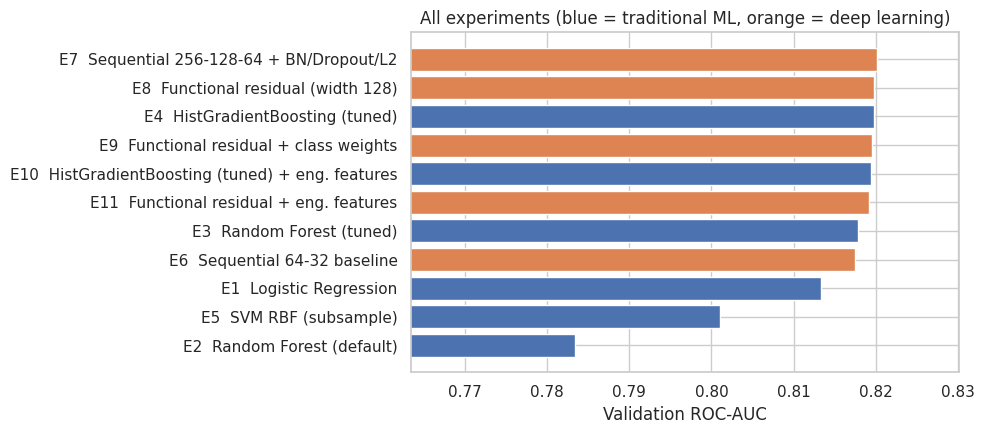

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.5))
order = res.sort_values("val_roc_auc")
colors = order["family"].map({"Traditional ML": "#4c72b0", "Deep Learning": "#dd8452"})
ax.barh(order["exp_id"] + "  " + order["model"], order["val_roc_auc"], color=colors)
ax.set_xlim(max(0.5, order["val_roc_auc"].min() - 0.02), order["val_roc_auc"].max() + 0.01)
ax.set_xlabel("Validation ROC-AUC"); ax.set_title("All experiments (blue = traditional ML, orange = deep learning)")
savefig("results_overview"); plt.show()

## 8. Final evaluation on the held-out test set

The best traditional model and the best deep learning model are chosen **by validation ROC-AUC**, the decision threshold is chosen **on validation data** (the one that maximises F1), and only then are both evaluated once on the test set. This avoids tuning anything on the test data.

In [ ]:
res = pd.DataFrame(RESULTS)
best_sk = res[res.family == "Traditional ML"].sort_values("val_roc_auc").iloc[-1]
best_dl = res[res.family == "Deep Learning"].sort_values("val_roc_auc").iloc[-1]
FINAL = {}
for label, row in [("Traditional ML", best_sk), ("Deep Learning", best_dl)]:
    m = MODELS[row.exp_id]
    Xte = D[m["features"]][2]
    p_te = score(m["model"], Xte) if m["kind"] == "sklearn" else \
        m["model"].predict(make_ds(Xte, yte), verbose=0).ravel()
    thr = best_threshold(yva, VAL_PROBA[row.exp_id])
    FINAL[label] = dict(exp_id=row.exp_id, name=row.model, p_test=p_te, thr=thr, features=m["features"], model=m["model"])
    print(f"{label}: {row.exp_id} {row.model} (val AUC {row.val_roc_auc:.4f}), F1-optimal threshold on val = {thr:.3f}")

rows = []
for label, f in FINAL.items():
    for tname, t in [("0.50", 0.5), (f"{f['thr']:.2f} (val-tuned)", f["thr"])]:
        rows.append({"model": f"{label}: {f['name']}", "threshold": tname, **metrics_at(yte, f["p_test"], t)})
test_table = pd.DataFrame(rows)
test_table.to_csv(ART_DIR / "test_results.csv", index=False)
display(test_table.round(4))
print(test_table.round(4).to_markdown(index=False))

Traditional ML: E4 HistGradientBoosting (tuned) (val AUC 0.8198), F1-optimal threshold on val = 0.234
Deep Learning: E7 Sequential 256-128-64 + BN/Dropout/L2 (val AUC 0.8202), F1-optimal threshold on val = 0.245


,model,threshold,accuracy,precision,recall,f1,balanced_acc,roc_auc,pr_auc
0,Traditional ML: HistGradientBoosting (tuned),0.50,0.8547,0.5914,0.1616,0.2539,0.5707,0.8164,0.4390
1,Traditional ML: HistGradientBoosting (tuned),0.23 (val-tuned),0.7893,0.3821,0.6118,0.4704,0.7166,0.8164,0.4390
2,Deep Learning: Sequential 256-128-64 + BN/Drop...,0.50,0.8536,0.6144,0.1147,0.1933,0.5509,0.8162,0.4329
3,Deep Learning: Sequential 256-128-64 + BN/Drop...,0.24 (val-tuned),0.7862,0.3797,0.6279,0.4732,0.7213,0.8162,0.4329


| model                                                | threshold        |   accuracy |   precision |   recall |     f1 |   balanced_acc |   roc_auc |   pr_auc |
|:-----------------------------------------------------|:-----------------|-----------:|------------:|---------:|-------:|---------------:|----------:|---------:|
| Traditional ML: HistGradientBoosting (tuned)         | 0.50             |     0.8547 |      0.5914 |   0.1616 | 0.2539 |         0.5707 |    0.8164 |   0.439  |
| Traditional ML: HistGradientBoosting (tuned)         | 0.23 (val-tuned) |     0.7893 |      0.3821 |   0.6118 | 0.4704 |         0.7166 |    0.8164 |   0.439  |
| Deep Learning: Sequential 256-128-64 + BN/Dropout/L2 | 0.50             |     0.8536 |      0.6144 |   0.1147 | 0.1933 |         0.5509 |    0.8162 |   0.4329 |
| Deep Learning: Sequential 256-128-64 + BN/Dropout/L2 | 0.24 (val-tuned) |     0.7862 |      0.3797 |   0.6279 | 0.4732 |         0.7213 |    0.8162 |   0.4329 |


### 8.1 Confusion matrices
Shown at the validation-tuned threshold. Rows are the true class and columns the prediction. In screening, the bottom-left cell (false negatives, true cases the model misses) is usually the costly one.

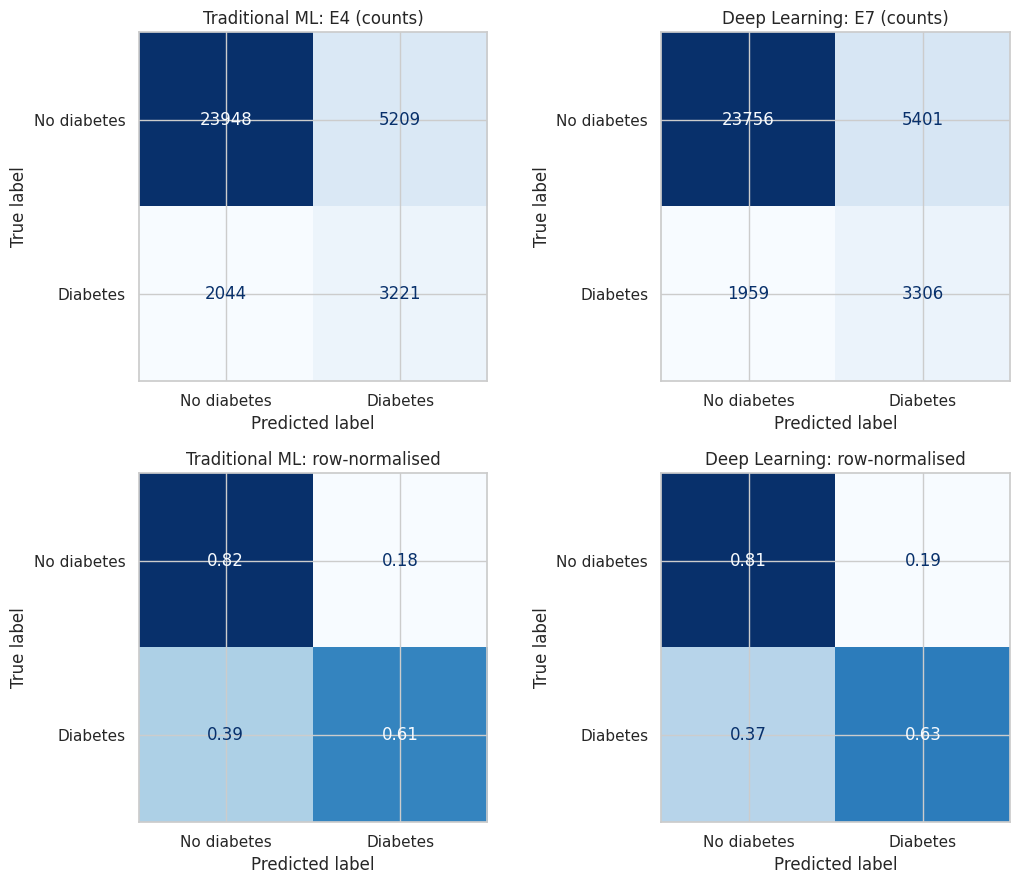


Traditional ML (E4)
              precision    recall  f1-score   support

 No diabetes      0.921     0.821     0.868     29157
    Diabetes      0.382     0.612     0.470      5265

    accuracy                          0.789     34422
   macro avg      0.652     0.717     0.669     34422
weighted avg      0.839     0.789     0.808     34422


Deep Learning (E7)
              precision    recall  f1-score   support

 No diabetes      0.924     0.815     0.866     29157
    Diabetes      0.380     0.628     0.473      5265

    accuracy                          0.786     34422
   macro avg      0.652     0.721     0.670     34422
weighted avg      0.841     0.786     0.806     34422



In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for j, (label, f) in enumerate(FINAL.items()):
    pred = (f["p_test"] >= f["thr"]).astype(int)
    ConfusionMatrixDisplay.from_predictions(yte, pred, ax=axes[0, j], cmap="Blues", colorbar=False,
                                            display_labels=["No diabetes", "Diabetes"], values_format="d")
    axes[0, j].set_title(f"{label}: {f['exp_id']} (counts)")
    ConfusionMatrixDisplay.from_predictions(yte, pred, ax=axes[1, j], cmap="Blues", colorbar=False, normalize="true",
                                            display_labels=["No diabetes", "Diabetes"], values_format=".2f")
    axes[1, j].set_title(f"{label}: row-normalised")
savefig("confusion_matrices"); plt.show()
for label, f in FINAL.items():
    print(f"\n{label} ({f['exp_id']})"); print(classification_report(yte, (f['p_test'] >= f['thr']).astype(int), digits=3,
                                                                      target_names=["No diabetes", "Diabetes"]))

My Iinterpretation (confusion matrices): At the validation-tuned threshold (0.23), E4 catches 3,221 of the 5,265 true cases (recall 0.61) and misses 2,044. It also flags 5,209 healthy people, so precision is only 0.38: about 6 in 10 flagged people are false alarms. E7 is almost identical: 3,306 caught, 1,959 missed, 5,401 false alarms. In raw counts false positives are the most common error, but the costlier one is the false negatives, since 37 to 39% of people with diabetes are told they are fine. For a screening tool I would accept more false alarms to get fewer misses, because a follow-up test is cheap compared with undiagnosed diabetes. The false alarm load is still big (about 18% of healthy people), and a clinic would need to be able to handle that.

### 8.2 ROC and precision-recall curves
ROC-AUC measures ranking quality across thresholds but can look optimistic when negatives dominate. The precision-recall curve is more informative under imbalance because it ignores true negatives; the dotted line marks the no-skill precision, which equals the positive rate.

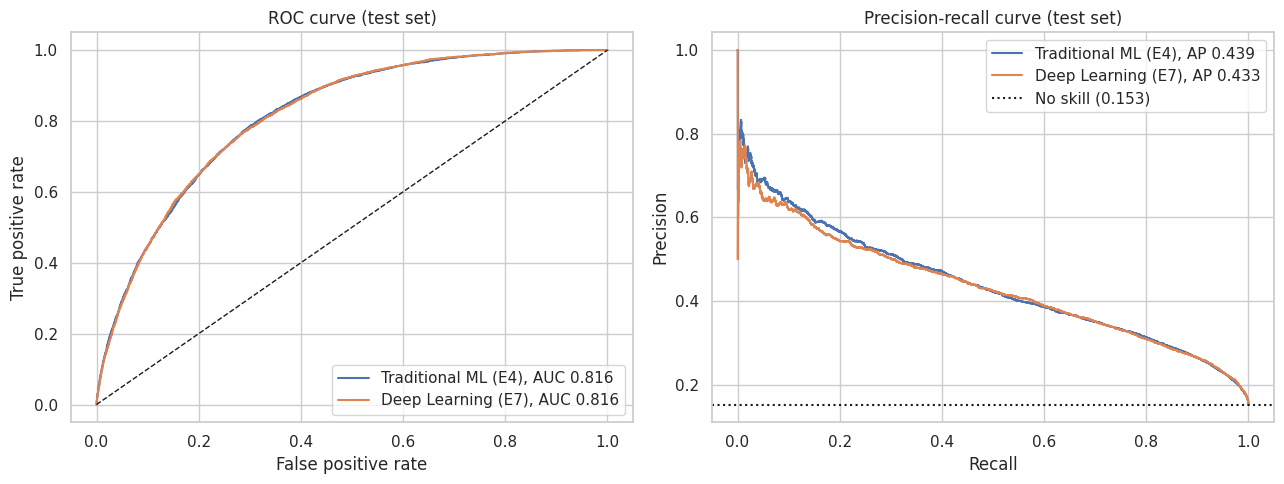

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for label, f in FINAL.items():
    fpr, tpr, _ = roc_curve(yte, f["p_test"]); axes[0].plot(fpr, tpr, label=f"{label} ({f['exp_id']}), AUC {roc_auc_score(yte, f['p_test']):.3f}")
    pr, rc, _ = precision_recall_curve(yte, f["p_test"]); axes[1].plot(rc, pr, label=f"{label} ({f['exp_id']}), AP {average_precision_score(yte, f['p_test']):.3f}")
axes[0].plot([0, 1], [0, 1], "k--", lw=1); axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curve (test set)"); axes[0].legend(loc="lower right")
axes[1].axhline(yte.mean(), color="k", ls=":", label=f"No skill ({yte.mean():.3f})")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision-recall curve (test set)"); axes[1].legend()
savefig("roc_pr_curves"); plt.show()

My Interpretation (ROC and PR): The two ROC curves sit on top of each other (test AUC 0.816 for both) and the PR curves almost overlap too (AP 0.439 for E4, 0.433 for E7), with E4 slightly ahead at low recall. So the two families are equal on this data. The PR curve shows what ROC hides: because only 15% are positive, precision falls as recall rises, to about 0.38 at recall 0.6, and it stays above the no-skill line (0.153) until recall gets close to 1. So the model is clearly useful but not very precise. The spike of high precision at the far left is based on very few cases and is noisy, so I would not rely on it. At the operating point I would actually use, precision is about 0.38 at recall of 0.61 to 0.63.

### 8.3 Learning curves and bias-variance diagnosis

**Deep learning:** training versus validation loss and AUC per epoch for the best network. **Traditional ML:** ROC-AUC versus training-set size for the best tree model. Parallel curves close together indicate high bias (underfitting; more capacity helps), a persistent gap indicates variance (overfitting; regularisation or more data helps), and a curve still rising at the right edge means more data would help.

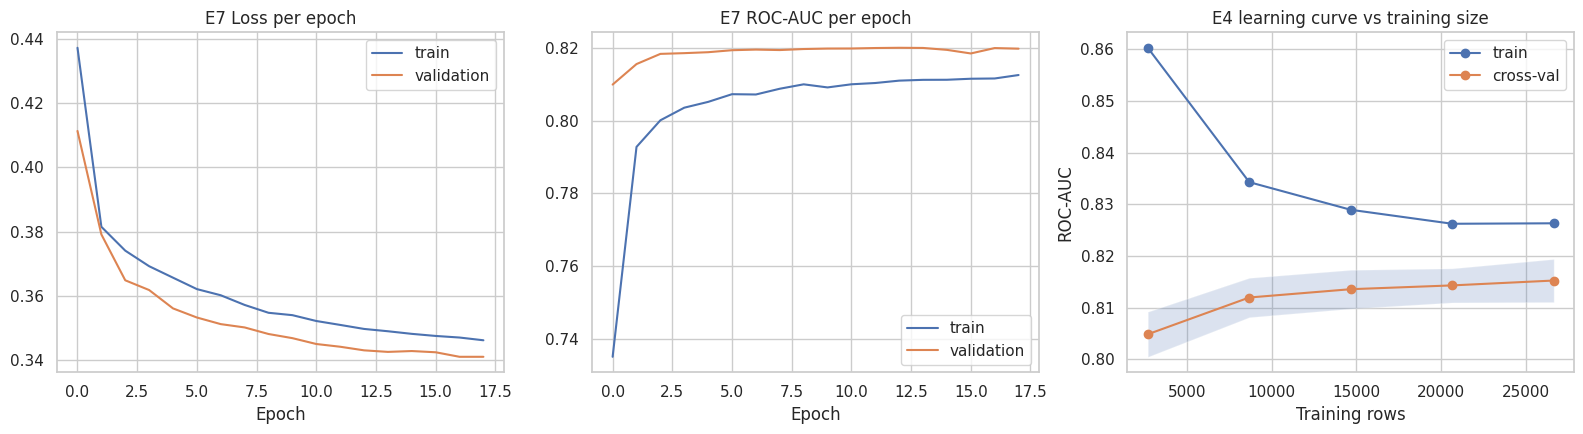

In [ ]:
h = HISTORIES[FINAL["Deep Learning"]["exp_id"]]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, key, title in zip(axes[:2], ["loss", "auc"], ["Loss", "ROC-AUC"]):
    ax.plot(h[key], label="train"); ax.plot(h["val_" + key], label="validation")
    ax.set_title(f"{FINAL['Deep Learning']['exp_id']} {title} per epoch"); ax.set_xlabel("Epoch"); ax.legend()

sk = FINAL["Traditional ML"]
Xtr_sk = D[sk["features"]][0]
sizes, tr_sc, va_sc = learning_curve(clone(sk["model"]), Xtr_sk[TUNE_IDX], ytr[TUNE_IDX], train_sizes=np.linspace(0.1, 1.0, 5),
                                     cv=3, scoring="roc_auc", n_jobs=-1, shuffle=True, random_state=SEED)
axes[2].plot(sizes, tr_sc.mean(1), "o-", label="train"); axes[2].plot(sizes, va_sc.mean(1), "o-", label="cross-val")
axes[2].fill_between(sizes, va_sc.mean(1) - va_sc.std(1), va_sc.mean(1) + va_sc.std(1), alpha=0.2)
axes[2].set_title(f"{sk['exp_id']} learning curve vs training size"); axes[2].set_xlabel("Training rows"); axes[2].set_ylabel("ROC-AUC"); axes[2].legend()
savefig("learning_curves"); plt.show()

In [ ]:
bv = res[["exp_id", "model", "train_auc", "val_roc_auc"]].copy()
bv["gap (variance proxy)"] = bv["train_auc"] - bv["val_roc_auc"]
bv["1 - val AUC (bias proxy)"] = 1 - bv["val_roc_auc"]
display(bv.round(4).sort_values("gap (variance proxy)", ascending=False))

,exp_id,model,train_auc,val_roc_auc,gap (variance proxy),1 - val AUC (bias proxy)
1,E2,Random Forest (default),0.9999,0.7834,0.2166,0.2166
2,E3,Random Forest (tuned),0.8491,0.8178,0.0312,0.1822
4,E5,SVM RBF (subsample),0.8292,0.8010,0.0282,0.1990
5,E6,Sequential 64-32 baseline,0.8250,0.8175,0.0075,0.1825
10,E11,Functional residual + eng. features,0.8224,0.8192,0.0031,0.1808
9,E10,HistGradientBoosting (tuned) + eng. features,0.8221,0.8194,0.0026,0.1806
3,E4,HistGradientBoosting (tuned),0.8221,0.8198,0.0023,0.1802
7,E8,Functional residual (width 128),0.8218,0.8198,0.0020,0.1802
8,E9,Functional residual + class weights,0.8213,0.8195,0.0018,0.1805
6,E7,Sequential 256-128-64 + BN/Dropout/L2,0.8215,0.8202,0.0013,0.1798


My Interpretation (learning curves, bias-variance): For E7, training and validation loss fall together and end close (about 0.346 and 0.341). Validation looks slightly better than training, which seems odd but is expected: dropout and batch norm are active during training, and training metrics are averaged over the epoch while the weights are still changing. It is not leakage, since test AUC (0.816) is close to validation AUC (0.820). Validation AUC levels off around 0.82 after about epoch 5, peaks near epoch 12, and early stopping ended the run at about epoch 17, so more training after epoch 5 gives almost nothing. For E4, the learning curve (on the 40k tuning subsample with 3-fold CV, so about 27k training rows at the right edge) shows train AUC falling from 0.86 to 0.83 and CV AUC rising from 0.805 to 0.815, so the gap closes to about 0.01. The CV curve is nearly flat at the end, so more rows would give only a small gain. This looks like a ceiling set by the features, not by model capacity.

On bias and variance: E2 has by far the biggest gap (0.217), clear high variance. E3 (0.031) and E5 (0.028) have mild variance. Everything else has a gap under 0.01 (E7 0.0013, E4 0.0023), so variance is under control. At the same time the bias proxy (1 minus validation AUC) is stuck at about 0.18 for every regularised model, from logistic regression (0.187) to E7 (0.180). Models with very different capacity reach the same error, so the remaining error is mostly bias from the features and label noise, which a bigger model will not fix. Logistic regression's gap is slightly negative (-0.002) because train AUC was measured on a 30k subsample, so that is just noise.

### 8.4 Error analysis: which features matter, and who the model fails

Permutation importance on the validation set (for the best traditional model) shows which inputs the model relies on. The subgroup table then reports true-positive rate (recall) and false-positive rate by age band, income band and sex at the tuned threshold. Large differences across groups would mean the screening tool is not equally reliable for everyone, which matters for a project aimed at under-served populations. Age and income are BRFSS category codes; check the band cut-offs against the dataset codebook before quoting them.

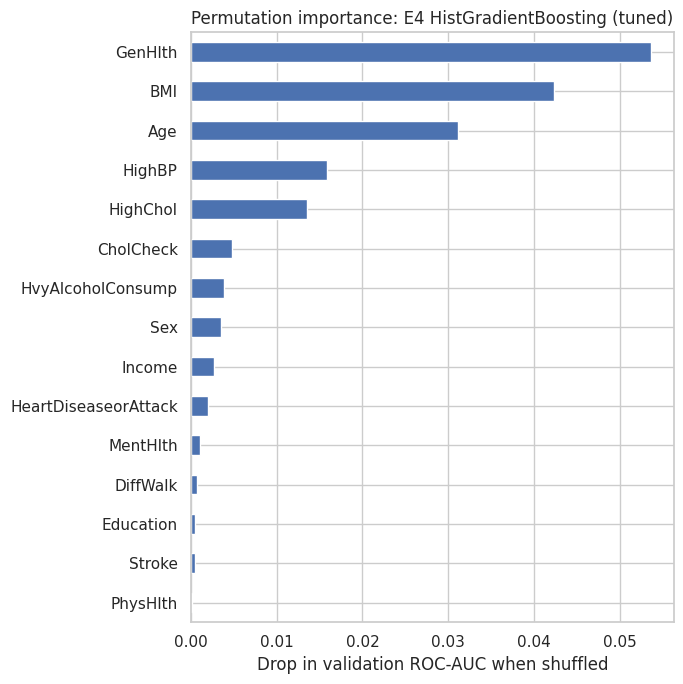

In [ ]:
m = sk["model"]; Xva_sk = D[sk["features"]][1]
sub = np.random.RandomState(SEED).choice(len(yva), size=min(10_000, len(yva)), replace=False)
pi = permutation_importance(m, Xva_sk[sub], yva[sub], scoring="roc_auc", n_repeats=3, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FEATURE_NAMES[sk["features"]]).sort_values()
plt.figure(figsize=(7, 7)); imp.tail(15).plot.barh(color="#4c72b0")
plt.xlabel("Drop in validation ROC-AUC when shuffled"); plt.title(f"Permutation importance: {sk['exp_id']} {sk['name']}")
savefig("permutation_importance"); plt.show()

In [ ]:
def group_report(df, p, thr, col, bins, labels):
    g = pd.cut(df[col], bins=bins, labels=labels)
    pred = (p >= thr).astype(int); y = df[TARGET].values.astype(int); out = []
    for lab in labels:
        k = (g == lab).values
        if k.sum() == 0: continue
        tp = ((pred == 1) & (y == 1) & k).sum(); fn = ((pred == 0) & (y == 1) & k).sum()
        fp = ((pred == 1) & (y == 0) & k).sum(); tn = ((pred == 0) & (y == 0) & k).sum()
        out.append({"attribute": col, "group": lab, "n": int(k.sum()), "prevalence": y[k].mean(),
                    "recall (TPR)": tp / max(tp + fn, 1), "FPR": fp / max(fp + tn, 1), "precision": tp / max(tp + fp, 1)})
    return out

p_best, thr_best = sk["p_test"], sk["thr"]
rows  = group_report(dte, p_best, thr_best, "Age", [0, 4, 8, 13], ["18-39", "40-59", "60+"])
rows += group_report(dte, p_best, thr_best, "Income", [0, 3, 6, 8], ["low (1-3)", "middle (4-6)", "high (7-8)"])
rows += group_report(dte, p_best, thr_best, "Sex", [-1, 0, 1], ["Sex=0", "Sex=1"])
grp = pd.DataFrame(rows); grp.to_csv(ART_DIR / "subgroup_errors.csv", index=False)
display(grp.round(3))

,attribute,group,n,prevalence,recall (TPR),FPR,precision
0,Age,18-39,5122,0.037,0.191,0.014,0.340
1,Age,40-59,12197,0.126,0.521,0.114,0.397
2,Age,60+,17103,0.207,0.673,0.290,0.378
3,Income,low (1-3),5718,0.241,0.737,0.334,0.412
4,Income,middle (4-6),12028,0.173,0.649,0.215,0.386
5,Income,high (7-8),16676,0.108,0.473,0.109,0.346
6,Sex,Sex=0,19235,0.143,0.602,0.159,0.387
7,Sex,Sex=1,15187,0.166,0.622,0.204,0.377


In [ ]:
# Most confident mistakes of the best traditional model: what do they look like?
d = dte.copy(); d["p"] = p_best; d["y"] = yte; d["pred"] = (p_best >= thr_best).astype(int)
fn = d[(d.y == 1) & (d.pred == 0)].sort_values("p").head(500)
tp = d[(d.y == 1) & (d.pred == 1)]
cmp_cols = ["BMI", "Age", "GenHlth", "HighBP", "HighChol", "PhysActivity", "Income"]
display(pd.DataFrame({"missed cases (lowest scores)": fn[cmp_cols].mean(), "correctly found cases": tp[cmp_cols].mean()}).round(2))

,missed cases (lowest scores),correctly found cases
BMI,27.28,34.10
Age,7.61,9.68
GenHlth,2.23,3.69
HighBP,0.25,0.90
HighChol,0.33,0.79
PhysActivity,0.77,0.57
Income,6.03,4.78


**My Interpretation (error analysis):** GenHlth, BMI and Age are the top three features by permutation importance (AUC drops of about 0.054, 0.042 and 0.031 when shuffled), followed by HighBP and HighChol. That matches clinical knowledge: age, weight and blood pressure are known risk factors for type 2 diabetes. GenHlth being first is worth a note, since it is self-rated and may partly reflect people who already know they have diabetes. PhysHlth and DiffWalk have near-zero importance even though they correlate with the target, probably because their information overlaps with GenHlth (I did not test this). Heavy alcohol use shows some importance but is negatively correlated with the target, so that is a pattern in this survey and not a causal link.

At the 0.23 threshold, recall depends strongly on age: 0.19 for ages 18-39, 0.52 for 40-59 and 0.67 for 60+. The youngest group has only 3.7% prevalence, so the model rarely flags them and misses most of the cases there. The 60+ group has high recall but also a false positive rate of 0.29. By income, the low band has recall 0.74 and FPR 0.33, while the high band has recall 0.47 and FPR 0.11. Low-income respondents have higher prevalence (24% vs 11%), so one global threshold flags many more of them: more true cases found, but more false alarms too. Sex is close (recall 0.60 vs 0.62, FPR 0.16 vs 0.20). For my mission this matters: the tool is not equally reliable for everyone, and one threshold is not fair across age groups, so group-specific thresholds would be worth testing.

The 500 lowest-scoring missed cases look healthier on paper than the cases the model finds: BMI 27 vs 34, high blood pressure 25% vs 90%, high cholesterol 33% vs 79%, better general health (2.2 vs 3.7) and more physical activity. These are people with diabetes who do not have the usual risk profile, and survey answers cannot separate them from healthy respondents.

**Dataset limitations.** The answers are self-reported (recall and reporting bias). The data is from one year (2015) and one country (the US), so it may not represent East Africa, including Rwanda. The label merges prediabetes and diabetes. Classes are imbalanced (about 15% positive). There are no clinical measurements such as blood glucose or HbA1c. Ordinal codes like age, income and education are treated as numbers. Removing duplicates may have dropped some genuine respondents.

**Improvements to propose:** Calibrate the probabilities and pick the threshold with a cost-based rule agreed with clinicians. Test group-specific thresholds and check fairness across age and income. Compare SMOTE or focal loss against class weights. Repeat runs with several seeds or cross-validation to get confidence intervals, since differences like 0.0004 AUC between E4 and E7 cannot be ranked from one split. Add clinical features if available, and validate on locally collected data before any real use.





## 9. Saving artifacts for Google Drive

The Drive folder must contain (1) the zipped raw dataset and (2) the best traditional model and best deep learning model. The scikit-learn model is saved together with its preprocessing so it can be loaded and used directly. The Keras model is saved as `.h5`, in the native `.keras` format and as a TensorFlow SavedModel.

In [ ]:
sk, dl = FINAL["Traditional ML"], FINAL["Deep Learning"]
joblib.dump({"model": sk["model"], "preprocessor": PREP[sk["features"]], "feature_set": sk["features"],
             "columns": FEATURE_NAMES[sk["features"]], "bmi_caps": BMI_CAPS, "threshold": sk["thr"],
             "exp_id": sk["exp_id"]}, ART_DIR / "best_traditional_model.joblib")

dl["model"].save(ART_DIR / "best_keras_model.h5")
dl["model"].save(ART_DIR / "best_keras_model.keras")
try:
    dl["model"].export(str(ART_DIR / "best_keras_savedmodel"))
except Exception as e:
    print("SavedModel export skipped:", repr(e)[:120])
joblib.dump({"preprocessor": PREP[dl["features"]], "columns": FEATURE_NAMES[dl["features"]], "bmi_caps": BMI_CAPS,
             "threshold": dl["thr"], "exp_id": dl["exp_id"]}, ART_DIR / "keras_preprocessing.joblib")

# zip the raw dataset for the Drive folder (data itself is git-ignored)
shutil.make_archive(str(ART_DIR / "raw_dataset"), "zip", DATA_DIR)
print(sorted(p.name for p in ART_DIR.iterdir()))

# reload check: the saved scikit-learn bundle must reproduce the test AUC
b = joblib.load(ART_DIR / "best_traditional_model.joblib")
Xchk = b["preprocessor"].transform(dte[b["columns"]])
print("Reloaded model test ROC-AUC:", round(roc_auc_score(yte, score(b["model"], Xchk)), 4))

Saved artifact at 'artifacts/best_keras_savedmodel'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 21), dtype=tf.float32, name='keras_tensor_6')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  133045029893328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133045029894480: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133045029894864: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133045029894672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133045029895440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133045029893904: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133045029895824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133045029892944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133045029895632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133045029896016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133045

In [ ]:
import shutil
from google.colab import files
for d in ["artifacts", "figures", "logs"]:
    shutil.make_archive(f"export_{d}", "zip", d)
    files.download(f"export_{d}.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Conclusions
The two paradigms ended up equal on this problem. On the held-out test set the tuned gradient boosting model (E4) and the regularised Sequential network (E7) both reached ROC-AUC 0.816, and eight of the eleven validation runs finished within 0.003 AUC of each other. The cheaper models are therefore the better choice here: logistic regression reaches 0.813 in under a second and boosting trains in about nine seconds, while the networks need 30 to 55 seconds. Class weighting and threshold tuning mattered more than model choice for a screening use case, moving recall from about 0.16 to between 0.61 and 0.63 at a precision of about 0.38. The learning curves and the flat tuning results suggest that the ceiling comes from the survey features and not from model capacity, and the engineered features added nothing. The models rank people sensibly but are not precise: about six in ten flagged people are false alarms and roughly 38% of true cases are missed. Error rates also differ by age and income, so one global threshold is not equally reliable for everyone. These models are not for diagnosis, and because they are trained on US survey data from 2015 they need validation on local data before any use in Rwanda. The most valuable next steps are adding clinical measurements and testing group-specific thresholds.

**Reproducibility.** Seeds are fixed (`SEED = 42`), the split is stratified and deterministic, all dependencies are in `requirements.txt`, tuning logs are in `artifacts/`, and every run is logged under `logs/` (W&B offline and TensorBoard). To view the logs: `tensorboard --logdir logs/tensorboard`, and `wandb sync logs/wandb/offline-run-*` if you want them online.